**AICE Associate <font color=red>모의고사 (문제)</font>** — AICE_Asso_013_초급_회귀_공공자전거수요예측

### **미래그린의 <span style="color:darkgreen">시간당 대여 건수</span> 예측 프로젝트**
---

- 도메인 : 공공자전거 수요 예측
- 목  표 : 대여소의 시간당 대여 건수를 예측하는 인공지능모델 개발
- 운영팀은 기상·시간 정보로 수요를 예측해 자전거 재배치를 효율화하려 한다.
- 시간대별 자전거 쏠림으로 미래그린의 재배치 비용이 커지고 있다.
- 대여소 1,860건 안팎의 이력 데이터를 활용할 수 있다.
- 모델이 시간당 대여 건수를 신뢰할 만한 수준으로 예측하면 현업의 대응 비용을 줄일 수 있을 것으로 기대한다.

---

#### **[유의사항]**
- 각 문항의 답은 `# (번호) 정답을 입력하세요` 셀의 `정답01` ~ `정답14` 변수에 **값만** 입력합니다. 채점은 이 값으로만 합니다.
- 숫자는 문항이 안내한 자릿수로 반올림해 입력하고, 글자는 따옴표로 감싸 입력하세요(예: `정답01 = 'pandas'`).
- 답을 구하는 코드는 문항의 작업 셀에 작성하고 실행하세요. 제공된 문항 셀을 삭제하지 마세요.
- 문항에 변수명이 제시된 경우 반드시 해당 변수명을 사용하세요. 앞 문항의 결과를 뒤 문항이 이어서 사용합니다.
- 막히면 문항 아래 접혀 있는 **힌트 1·2·3단계**를 순서대로 펼쳐 보세요. 단계가 올라갈수록 정답에 가까워집니다.
- 모든 데이터는 가상으로 생성한 합성데이터이며, 실제 AICE 시험문항의 원문을 복제하지 않았습니다.

#### **[학습 정보]**
- 학습 목표 : 미래그린의 데이터로 대여소의 시간당 대여 건수를 예측하는 AI 모델을 만들며 데이터 분석·전처리·모델링 전 과정을 수행할 수 있다
- AICE 역량 : 데이터 분석(DA1 분석 환경 구성, DA2 데이터 불러오기·구조 파악, DA3 탐색적 데이터 분석, DA4 데이터 시각화) / 데이터 전처리(DP1 이상치 처리, DP2 결측치 처리, DP3 인코딩·변수 변환, DP4 데이터 분할, DP5 스케일링) / AI 모델링(AM1 머신러닝 모델 학습·탐색, AM2 모델 해석, AM3 모델 성능 평가, AM4 딥러닝 모델 구성·학습, AM5 딥러닝 학습 결과 분석)
- 기술 스택 : pandas(import pandas as pd, read_csv, head, median, groupby, quantile, drop, reset_index, dropna, sum, isnull, get_dummies, info, DataFrame, columns, sort_values, shape) · seaborn(import seaborn as sns, scatterplot) · matplotlib(import matplotlib.pyplot as plt, show, plot, title, xlabel, ylabel, legend) · scikit-learn(train_test_split, RobustScaler, fit_transform, transform, KNeighborsRegressor, fit, RandomForestRegressor, feature_importances_, score) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit, Dense, Dropout, history)
- 난이도 : 초급 (설계 난이도 점수 2.38 / 5)
- 예상 소요 시간 : 약 108분 (문항별 시간은 각 문항 제목 아래)
- 관련 도메인 : 공공자전거 수요 예측 (교통·물류)

**[ 데이터 컬럼 설명 (데이터 파일명: data.csv) ]**

- UID                   : 고유 식별번호
- TEMP_C                : 기온(℃)
- HUMIDITY              : 습도(%)
- RAINFALL_MM           : 강수량(mm)
- HOUR                  : 시각(시)
- VISIBILITY_M          : 가시거리(m)
- STATION_POP           : 반경 500m 거주 인구(천명)
- PREV_HOUR_RENT        : 직전 시간 대여 수
- HOLIDAY               : 휴일 여부
- DISTRICT              : 구역
- WEATHER               : 날씨
- RENTALS               : 시간당 대여 건수

## <font color=blue>**<데이터 분석 (20점)>**</font>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요.**

In [1]:
import numpy as np

### **1. 분석에 필요한 라이브러리 두 개를 아래 가이드의 별칭으로 한 번에 불러오세요.**

<sub>학습 목표: 분석에 필요한 파이썬 라이브러리를 관용 별칭으로 불러올 수 있다 | 역량: DA1 분석 환경 구성 | 기술: seaborn(import seaborn as sns) · matplotlib(import matplotlib.pyplot as plt) | 난이도: 기초 | 예상 시간: 3분</sub>

- `matplotlib.pyplot` -> 별칭 `plt`
- `seaborn` -> 별칭 `sns`
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답01]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답01]** 의 값만 답안 셀에 `정답01 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [2]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# (1) 정답을 입력하세요 — `정답01` 에 값만 넣고 실행하세요

정답01 = 'seaborn'

<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

라이브러리마다 import 문을 따로 작성하고 각각 별칭을 붙입니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `import ... as ...`. 정답은 7글자이고 첫 글자는 `s` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 1번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import matplotlib.pyplot as plt
import seab___ as sns

정답01 = 'seab___'   # 빈칸에 넣은 단어
```

</details>

### **2. AI 모델링을 위해 분석 및 처리할 데이터 파일을 읽어오려고 합니다. pandas로 데이터 파일을 읽어온 뒤, 데이터프레임 변수명 data 에 할당하고 첫 5개 행을 출력하세요.**

<sub>학습 목표: CSV 파일을 데이터프레임으로 읽고 행·열 구성을 확인할 수 있다 | 역량: DA2 데이터 불러오기·구조 파악 | 기술: pandas(import pandas as pd, read_csv, head) | 난이도: 기초 | 예상 시간: 4분</sub>

- 제시된 가이드에 맞춰 코드를 작성하고 실행하세요
    - 데이터프레임 변수명 : data
    - 데이터 파일명 : data.csv
    - 파일은 본 문제/답안지와 동일한 경로에 있습니다
- **[정답02]** 읽어 온 데이터의 **열(column)의 개수** 를 작성하세요
- 답안 : **[정답02]** 의 값만 답안 셀에 `정답02 = 값` 형태로 입력하세요
- 배점 : 5점

---

In [3]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

import pandas as pd

data = pd.read_csv('./data.csv')
data.head(5)

print(data.shape[1])


12


In [ ]:
# (2) 정답을 입력하세요 — `정답02` 에 값만 넣고 실행하세요

정답02 = '12'

<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

파일 형식(csv/json/구분자)에 맞는 pandas 읽기 함수와 옵션을 고르세요. 읽어 온 data 로 열(column)의 개수를 직접 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `pd.read_csv`, `shape`, `select_dtypes`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 2번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

data = pd.read_csv('./data.csv')
data.head(5)

# [정답02] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
print(data.shape[__])
```

</details>

### **3. 구역(DISTRICT) 별로 직전 시간 대여 수(PREV_HOUR_RENT)의 특성을 비교하려 합니다.**

<sub>학습 목표: 집계·통계량으로 데이터의 특징을 탐색할 수 있다 | 역량: DA3 탐색적 데이터 분석 | 기술: pandas(median, groupby) | 난이도: 쉬움 | 예상 시간: 4분</sub>

- 앞 문항 결과 사용 : 2번 `data`
- 구역(DISTRICT) 별 직전 시간 대여 수(PREV_HOUR_RENT)의 **중앙값** 을 구해 변수 `grp` 에 담으세요
    - 대상 데이터프레임 : data
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답03]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답03]** 의 값만 답안 셀에 `정답03 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [4]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

grp = data.groupby('DISTRICT')['PREV_HOUR_RENT'].median()
grp

,PREV_HOUR_RENT
DISTRICT,
공원,60.5
대학,53.0
도심,65.0
주거,59.0


In [ ]:
# (3) 정답을 입력하세요 — `정답03` 에 값만 넣고 실행하세요

정답03 = 'groupby'

<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

범주별로 묶어서 하나의 통계량을 구하는 패턴입니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `groupby`, `median`. 정답은 7글자이고 첫 글자는 `g` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 3번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
grp = data.grou___('DISTRICT')['PREV_HOUR_RENT'].median()
grp

정답03 = 'grou___'   # 빈칸에 넣은 단어
```

</details>

### **4. 습도(%)(HUMIDITY)와(과) 가시거리(m)(VISIBILITY_M)의 관계를 휴일 여부 별로 구분해 확인하려 합니다.**

<sub>학습 목표: 그래프로 변수의 분포와 관계를 시각화할 수 있다 | 역량: DA4 데이터 시각화 | 기술: seaborn(scatterplot) · matplotlib(show) | 난이도: 쉬움 | 예상 시간: 4분</sub>

- 앞 문항 결과 사용 : 1번 `plt`, `sns` · 2번 `data`
- 대상 데이터프레임 : data
- seaborn 의 scatterplot 으로 산점도를 그리세요
- X축: HUMIDITY, Y축: VISIBILITY_M
- 점의 색상은 HOLIDAY 로 구분(hue)하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답04]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답04]** 의 값만 답안 셀에 `정답04 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 55092 (\N{HANGUL SYLLABLE HYU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51068 (\N{HANGUL SYLLABLE IL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54217 (\N{HANGUL SYLLABLE PYEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


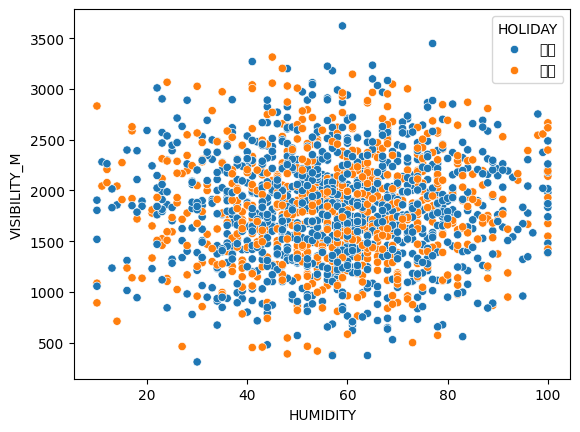

In [5]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

sns.scatterplot(data=data, x='HUMIDITY', y='VISIBILITY_M', hue='HOLIDAY')
plt.show()

In [ ]:
# (4) 정답을 입력하세요 — `정답04` 에 값만 넣고 실행하세요

정답04 = 'scatterplot'

<details><summary>힌트 1단계 (접근 방향) - 4번 문항</summary>

두 수치형 변수의 관계를 점으로 그리고 색으로 그룹을 구분합니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 4번 문항</summary>

사용할 도구: `sns.scatterplot`. 정답은 11글자이고 첫 글자는 `s` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 4번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
sns.scatte_____(data=data, x='HUMIDITY', y='VISIBILITY_M', hue='HOLIDAY')
plt.show()

정답04 = 'scatte_____'   # 빈칸에 넣은 단어
```

</details>

## <font color=blue>**<데이터 전처리 (30점)>**</font>

### **5. 그래프로 확인한 결과, 강수량(mm)(RAINFALL_MM) 컬럼에서 이상치가 발견되었습니다. AI모델링할 때 부정적 영향이 없도록 아래 가이드에 따라 이상치를 처리하세요.**

<sub>학습 목표: 사분위 범위(IQR) 등의 기준으로 이상치를 찾아 처리할 수 있다 | 역량: DP1 이상치 처리 | 기술: pandas(quantile, drop, reset_index) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 2번 `data`
- 대상 데이터프레임 : data
- 강수량(mm)(RAINFALL_MM)이(가) upper fence 값보다 크거나 lower fence 값보다 작은 이상치 행(row)을 삭제하세요 (IQR 기준 K=1.5)
- AI모델링에 불필요한 고유 식별번호(UID) 컬럼을 삭제하세요
- 전처리를 적용한 데이터프레임은 data_temp 라는 변수명으로 저장하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답05]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답05]** 의 값만 답안 셀에 `정답05 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 6점

---

In [6]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요

q1 = data['RAINFALL_MM'].quantile(0.25)
q3 = data['RAINFALL_MM'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

data_temp = data.drop( data[(data['RAINFALL_MM'] > upper_fence) | (data['RAINFALL_MM'] < lower_fence)].index, axis=0)
data_temp = data_temp.drop(columns=['UID'])
data_temp.reset_index(drop=True, inplace=True)

In [ ]:
# (5) 정답을 입력하세요 — `정답05` 에 값만 넣고 실행하세요

정답05 = 'reset_index'

<details><summary>힌트 1단계 (접근 방향) - 5번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. 인덱스를 0부터 다시 매기는 메서드입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 5번 문항</summary>

사용할 도구: `drop`, `quantile`, `reset_index`. 정답은 11글자이고 첫 글자는 `r` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 5번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
q1 = data['RAINFALL_MM'].quantile(0.25)
q3 = data['RAINFALL_MM'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

data_temp = data.drop( data[(data['RAINFALL_MM'] > upper_fence) | (data['RAINFALL_MM'] < lower_fence)].index, axis=0)
data_temp = data_temp.drop(columns=['UID'])
data_temp.reset______(drop=True, inplace=True)

정답05 = 'reset______'   # 빈칸에 넣은 단어
```

</details>

### **6. 제시된 가이드에 맞춰 결측치를 처리하고 검증하는데 에러가 나고 있습니다. 코드의 오류를 수정하세요.**

<sub>학습 목표: 결측치를 확인하고 삭제하거나 대체할 수 있다 | 역량: DP2 결측치 처리 | 기술: pandas(dropna, sum, isnull) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 5번 `data_temp`
- 코드의 오류를 수정하세요
    - 대상 데이터프레임 : data_temp
    - 결측치 개수를 확인한 뒤, 결측치가 있는 행을 모두 삭제해 data_na 에 담으세요
    - 처리 후 결측치가 사라졌는지 확인하세요
- **[정답06]** 처리 전 data_temp 의 결측치는 총 몇 개인가요?
- 답안 : **[정답06]** 의 값만 답안 셀에 `정답06 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [7]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

print('결측치 처리 전\n', data_temp.isnull().sum())
data_na = data_temp.dropna()
print('결측치 처리 후\n', data_na.isnull().sum())

data_temp.isnull().sum().sum()

결측치 처리 전
 TEMP_C             0
HUMIDITY          54
RAINFALL_MM        0
HOUR               0
VISIBILITY_M       0
STATION_POP        0
PREV_HOUR_RENT     0
HOLIDAY            0
DISTRICT           0
WEATHER            0
RENTALS            0
dtype: int64
결측치 처리 후
 TEMP_C            0
HUMIDITY          0
RAINFALL_MM       0
HOUR              0
VISIBILITY_M      0
STATION_POP       0
PREV_HOUR_RENT    0
HOLIDAY           0
DISTRICT          0
WEATHER           0
RENTALS           0
dtype: int64


np.int64(54)

In [ ]:
# (6) 정답을 입력하세요 — `정답06` 에 값만 넣고 실행하세요

정답06 = '54'

<details><summary>힌트 1단계 (접근 방향) - 6번 문항</summary>

결측치 확인 -> 삭제 -> 재확인 순서로 코드를 읽어 보세요. 결측치 처리 전 데이터프레임의 결측치 합계를 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 6번 문항</summary>

사용할 도구: `isnull`, `sum`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 6번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
print('결측치 처리 전\n', data_temp.isnull().sum())
data_na = data_temp.dropna()
print('결측치 처리 후\n', data_na.isnull().sum())

# [정답06] 실행한 결과를 입력하세요
data_temp.isnull().sum().sum()
```

</details>

### **7. 원-핫 인코딩은 범주형 데이터를 1과 0의 이진형 벡터로 변환하는 방법입니다. 아래 안내대로 범주형 데이터를 변환하는 코드를 바로잡으세요.**

<sub>학습 목표: 범주형 변수를 인코딩하고 변수를 정리·변환할 수 있다 | 역량: DP3 인코딩·변수 변환 | 기술: pandas(get_dummies, info) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 2번 `pd` · 6번 `data_na`
- 아래 가이드에 따라 인코딩하는데 실행 중 예외가 발생합니다. 코드의 오류를 정정하세요
    - 대상 데이터프레임 : data_na
    - 문자열(범주형) 컬럼 HOLIDAY, DISTRICT, WEATHER 을(를) get_dummies 로 인코딩하세요 (타깃 RENTALS 은 제외, drop_first=True)
    - 인코딩된 데이터프레임은 data_preset 에 저장하고 info() 로 구조를 확인하세요
- **[정답07]** 인코딩 후 data_preset 의 **전체 컬럼 개수**는 몇 개입니까?
- 답안 : **[정답07]** 의 값만 답안 셀에 `정답07 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [9]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

data_preset = pd.get_dummies(data=data_na, columns=['HOLIDAY', 'DISTRICT', 'WEATHER'], drop_first=True)
data_preset.info()

data_preset.shape[1]

<class 'pandas.core.frame.DataFrame'>
Index: 1615 entries, 0 to 1668
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   TEMP_C          1615 non-null   float64
 1   HUMIDITY        1615 non-null   float64
 2   RAINFALL_MM     1615 non-null   float64
 3   HOUR            1615 non-null   float64
 4   VISIBILITY_M    1615 non-null   float64
 5   STATION_POP     1615 non-null   float64
 6   PREV_HOUR_RENT  1615 non-null   float64
 7   RENTALS         1615 non-null   float64
 8   HOLIDAY_휴일      1615 non-null   bool   
 9   DISTRICT_대학     1615 non-null   bool   
 10  DISTRICT_도심     1615 non-null   bool   
 11  DISTRICT_주거     1615 non-null   bool   
 12  WEATHER_비       1615 non-null   bool   
 13  WEATHER_흐림      1615 non-null   bool   
dtypes: bool(6), float64(8)
memory usage: 123.0 KB


14

In [ ]:
# (7) 정답을 입력하세요 — `정답07` 에 값만 넣고 실행하세요

정답07 = '14'

<details><summary>힌트 1단계 (접근 방향) - 7번 문항</summary>

get_dummies 호출의 인자 이름을 점검하세요. 인코딩이 끝난 데이터프레임의 컬럼 개수를 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 7번 문항</summary>

사용할 도구: `shape`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 7번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
data_preset = pd.get_dummies(data=data_na, columns=['HOLIDAY', 'DISTRICT', 'WEATHER'], drop_first=True)
data_preset.info()

# [정답07] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
data_preset.shape[__]
```

</details>

### **8. 모델링 후에 모델의 성능을 평가할 수 있도록 훈련과 검증 각각에 사용할 데이터셋을 분리하려고 합니다. 아래 안내대로 분리하세요.**

<sub>학습 목표: 피처와 레이블을 나누고 훈련·검증 데이터로 분할할 수 있다 | 역량: DP4 데이터 분할 | 기술: pandas(drop) · scikit-learn(train_test_split) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 7번 `data_preset`
- 대상 데이터프레임 : data_preset
- 시간당 대여 건수(RENTALS) 컬럼을 레이블값 y 로, 나머지 컬럼을 피처값 X 로 대입하세요
- 훈련과 검증 데이터셋 분리 — 훈련 : 검증 = 70:30 (test_size=0.3)
- 난수 시드(random_state)는 11 로 설정하세요
- 변수명 : X_train, X_valid, y_train, y_valid (훈련 피처/검증 피처/훈련 레이블/검증 레이블)
- scikit-learn 의 train_test_split 함수를 활용하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답08]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답08]** 의 값만 답안 셀에 `정답08 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 6점

---

In [10]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

from sklearn.model_selection import train_test_split

X = data_preset.drop('RENTALS', axis=1)
y = data_preset['RENTALS']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.3, random_state=11)

In [ ]:
# (8) 정답을 입력하세요 — `정답08` 에 값만 넣고 실행하세요

정답08 = 'train_test_split'

<details><summary>힌트 1단계 (접근 방향) - 8번 문항</summary>

피처와 레이블을 나눈 뒤, 훈련/검증으로 무작위 분할합니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 8번 문항</summary>

사용할 도구: `train_test_split`, `drop`. 정답은 16글자이고 첫 글자는 `t` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 8번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
from sklearn.model_selection import train_test_split

X = data_preset.drop('RENTALS', axis=1)
y = data_preset['RENTALS']

X_train, X_valid, y_train, y_valid = train_te________(X, y, test_size=0.3, random_state=11)

정답08 = 'train_te________'   # 빈칸에 넣은 단어
```

</details>

### **9. 변수들의 단위(범위) 차이가 모델에 영향을 주지 않도록 스케일링하는 코드가 있습니다. 빈칸을 채워 완성하세요.**

<sub>학습 목표: 훈련 데이터로 스케일러를 학습해 검증 데이터에 같은 기준을 적용할 수 있다 | 역량: DP5 스케일링 | 기술: scikit-learn(RobustScaler, fit_transform, transform) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 8번 `X_train`, `X_valid`
- 훈련 데이터(X_train)는 변환 기준을 학습하면서 변환하고, 검증 데이터(X_valid)는 **학습된 기준으로 변환만** 합니다
- 사용할 스케일러 : RobustScaler
- **[정답09]** 스케일링 후 검증 데이터(X_valid)의 **최댓값**을 소수점 둘째 자리까지 기입하세요
- 답안 : **[정답09]** 의 값만 답안 셀에 `정답09 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [13]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요 (채점하지 않음)

from sklearn.preprocessing import RobustScaler

ss = RobustScaler()
X_train = ss.fit_transform(X_train)
X_valid = ss.transform(X_valid)

round(np.max(X_valid), 2)

np.float64(7.84)

In [ ]:
# (9) 정답을 입력하세요 — `정답09` 에 값만 넣고 실행하세요

정답09 = '7.84'

<details><summary>힌트 1단계 (접근 방향) - 9번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. 훈련 데이터로 변환 기준을 학습한 뒤 곧바로 변환까지 하는 메서드입니다. 변환된 검증 데이터 전체에서 최댓값을 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 9번 문항</summary>

사용할 도구: `RobustScaler`, `fit_transform`, `transform`, `np.max`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 9번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.preprocessing import RobustScaler

ss = RobustScaler()
X_train = ss.fit_transform(X_train)
X_valid = ss.transform(X_valid)

# [정답09] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(np.max(X_valid), __)
```

</details>

## <font color=blue>**<AI 모델링 (50점)>**</font>

### **10. 시간당 대여 건수(RENTALS)을(를) 예측하는 머신러닝 모델을 만들려고 합니다. KNN와(과) RandomForest는 각각 서로 다른 방식으로 예측하는 모델입니다.**

<sub>학습 목표: 머신러닝 모델에 하이퍼파라미터를 지정해 학습하고 결과를 확인할 수 있다 | 역량: AM1 머신러닝 모델 학습·탐색 | 기술: scikit-learn(KNeighborsRegressor, fit, RandomForestRegressor) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_train` · 9번 `X_train`
- KNN 모델을 아래와 같이 만들어 `knn` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : n_neighbors=15, weights='uniform'
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- RandomForest 모델을 아래와 같이 만들어 `rf` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : n_estimators=150, max_depth=4
    - 난수 시드(random_state) : 7
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- **[정답10]** 학습된 `knn`(KNN) 의 **훈련 데이터** 점수 `knn.score(X_train, y_train)` (결정계수(R2))를 소수점 셋째 자리까지 입력하세요
- 답안 : **[정답10]** 의 값만 답안 셀에 `정답10 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [14]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

from sklearn.neighbors import KNeighborsRegressor

knn = KNeighborsRegressor(n_neighbors=15, weights='uniform')
knn.fit(X_train, y_train)

from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=150, max_depth=4, random_state=7)
rf.fit(X_train, y_train)

round(knn.score(X_train, y_train), 3)

0.663

In [ ]:
# (10) 정답을 입력하세요 — `정답10` 에 값만 넣고 실행하세요

정답10 = '0.663'

<details><summary>힌트 1단계 (접근 방향) - 10번 문항</summary>

모델 객체를 하이퍼파라미터와 함께 만들고 훈련 데이터로 fit 합니다. 학습된 모델의 score 메서드에 훈련 데이터를 넣고 반올림하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 10번 문항</summary>

사용할 도구: `KNeighborsRegressor`, `fit`, `RandomForestRegressor`, `score`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 10번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.neighbors import KNeighborsRegressor

knn = KNeighborsRegressor(n_neighbors=15, weights='uniform')
knn.fit(X_train, y_train)

from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=150, max_depth=4, random_state=7)
rf.fit(X_train, y_train)

# [정답10] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(knn.score(X_train, y_train), __)
```

</details>

### **11. RandomForest 모델의 변수중요도 상위 3개 변수가 전체 설명력의 얼마를 차지하는지 확인할 계획입니다.**

<sub>학습 목표: 변수 중요도·계수로 모델이 어떤 변수에 의존하는지 해석할 수 있다 | 역량: AM2 모델 해석 | 기술: pandas(DataFrame, reset_index, head, columns) · scikit-learn(feature_importances_) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 2번 `pd` · 8번 `X` · 10번 `rf`
- 학습된 RandomForest 모델 `rf` 의 변수중요도를 변수명과 매핑한 DataFrame `fi` 로 만들고 내림차순 정렬하세요
    - 상위 3개 행을 `top_n` 에 보관하세요
- **[정답11]** 상위 3개 변수 중요도의 **합계**를 소수점 둘째 자리까지 기입하세요
- 답안 : **[정답11]** 의 값만 답안 셀에 `정답11 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [15]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

fi = pd.DataFrame({'feature': X.columns, 'importance': rf.feature_importances_})
fi = fi.sort_values('importance', ascending=False).reset_index(drop=True)
top_n = fi.head(3)

round(top_n['importance'].sum(), 2)


np.float64(0.96)

In [ ]:
# (11) 정답을 입력하세요 — `정답11` 에 값만 넣고 실행하세요

정답11 = '0.96'

<details><summary>힌트 1단계 (접근 방향) - 11번 문항</summary>

중요도 DataFrame 을 만들어 정렬한 뒤 위에서 N개를 선택합니다. top_n 의 importance 컬럼을 합하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 11번 문항</summary>

사용할 도구: `feature_importances_`, `sort_values`, `head`, `sum`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 11번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
fi = pd.DataFrame({'feature': X.columns, 'importance': rf.feature_importances_})
fi = fi.sort_values('importance', ascending=False).reset_index(drop=True)
top_n = fi.head(3)

# [정답11] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(top_n['____'].sum(), __)
```

</details>

### **12. RandomForest 모델의 기본 평가 점수를 `score` 메서드로 간단히 확인하려 합니다.**

<sub>학습 목표: 평가 지표로 두 모델의 성능을 비교할 수 있다 | 역량: AM3 모델 성능 평가 | 기술: scikit-learn(score) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_valid` · 9번 `X_valid` · 10번 `rf`
- 학습된 RandomForest 모델 `rf` 의 `score(X_valid, y_valid)` 값을 `score_rf` 에 저장하세요 (분류는 정확도, 회귀는 결정계수 R2 를 돌려줍니다)
- **[정답12]** `score_rf` 를 소수점 셋째 자리까지 기입하세요
- 답안 : **[정답12]** 의 값만 답안 셀에 `정답12 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [16]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

score_rf = rf.score(X_valid, y_valid)

round(score_rf, 3)


0.684

In [ ]:
# (12) 정답을 입력하세요 — `정답12` 에 값만 넣고 실행하세요

정답12 = '0.684'

<details><summary>힌트 1단계 (접근 방향) - 12번 문항</summary>

학습된 모델 객체의 score 메서드에 검증 데이터를 넣습니다. score 값을 반올림하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 12번 문항</summary>

사용할 도구: `score`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 12번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
score_rf = rf.score(X_valid, y_valid)

# [정답12] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(score_rf, __)
```

</details>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요. (tensorflow 필요)**

In [17]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import Input, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, RMSprop, Nadam, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(7)

### **13. 시간당 대여 건수(RENTALS)을(를) 예측하는 딥러닝 모델을 만들려고 합니다. 아래 가이드를 참고해서 모델링하고 학습을 수행하십시오.**

<sub>학습 목표: 주어진 구조대로 Keras 딥러닝 모델을 구성하고 학습할 수 있다 | 역량: AM4 딥러닝 모델 구성·학습 | 기술: pandas(shape) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit) | 난이도: 보통 | 예상 시간: 13분</sub>

- 앞 문항 결과 사용 : 8번 `y_train`, `y_valid` · 9번 `X_train`, `X_valid`
- tensorflow framework 를 사용하세요
- 은닉층은 Dense 레이어 2개(노드 수 [32, 16]), 활성화 함수는 'selu' 로 하세요
- 첫 번째 은닉층 뒤에 Dropout(0.5) 층을 두세요
- 출력층: 노드 1개, 활성화 함수 'linear'
- EarlyStopping 으로 5번의 epoch 동안 val_loss 가 향상되지 않으면 훈련을 중지(restore_best_weights=True)하도록 설정하고 estop 변수에 저장하세요
- optimizer 는 adam, loss 는 mse, metrics 는 [mae] 로 지정해서 모델을 컴파일하세요
- batch_size 는 128, epochs 는 50 로 학습하고 학습정보는 history 변수에 저장하세요 (검증 데이터: X_valid, 검증 레이블), 학습 진행 로그는 출력하지 않도록 verbose=0 으로 설정하세요
- 안내된 내용 외 별도의 파라미터를 입력하지 마세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답13]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답13]** 의 값만 답안 셀에 `정답13 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [18]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요

model = Sequential([
    Dense(32, activation='selu', input_dim=X_train.shape[1]),
    Dropout(0.5),
    Dense(16, activation='selu'),
    Dense(1, activation='linear')
])

estop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer='adam', loss='mse', metrics=['mae'])

history = model.fit(X_train, y_train,
                    epochs=50, batch_size=128,
                    validation_data=(X_valid, y_valid),
                    verbose=0,
                    callbacks=cb_list)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# (13) 정답을 입력하세요 — `정답13` 에 값만 넣고 실행하세요

정답13 = 'adam'

<details><summary>힌트 1단계 (접근 방향) - 13번 문항</summary>

가이드의 모델 구조·학습 조건을 코드의 각 줄과 대응시켜 보세요. 모델을 학습시킬 때 가중치를 갱신하는 최적화 알고리즘의 이름입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 13번 문항</summary>

사용할 도구: `Sequential`, `Dense`, `Dropout`, `EarlyStopping`, `model.compile`, `model.fit`. 정답은 4글자이고 첫 글자는 `a` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 13번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
model = Sequential([
    Dense(32, activation='selu', input_dim=X_train.shape[1]),
    Dropout(0.5),
    Dense(16, activation='selu'),
    Dense(1, activation='linear')
])

estop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer='ad__', loss='mse', metrics=['mae'])

history = model.fit(X_train, y_train,
                    epochs=50, batch_size=128,
                    validation_data=(X_valid, y_valid),
                    verbose=0,
                    callbacks=cb_list)

정답13 = 'ad__'   # 빈칸에 넣은 단어
```

</details>

### **14. 앞서 만든 딥러닝 모델의 일반화 성능을 평가하려고 합니다. matplotlib 라이브러리를 활용해서, 학습 Loss와(과) 검증 Loss의 변화를 그래프로 시각화하세요.**

<sub>학습 목표: 학습 기록으로 딥러닝 모델의 학습 과정과 성능을 분석할 수 있다 | 역량: AM5 딥러닝 학습 결과 분석 | 기술: matplotlib(plot, title, xlabel, ylabel) · TensorFlow(Keras)(history) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 1번 `plt` · 13번 `history`
- 1개의 그래프에 학습 Loss 과 검증 Loss 2가지를 모두 표시하세요
- 범례를 'train', 'val' 로 표시하세요
- 그래프의 타이틀은 'Model Loss' 로, X축 이름은 'Epochs', Y축 이름은 'Loss' 로 표시하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답14]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답14]** 의 값만 답안 셀에 `정답14 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

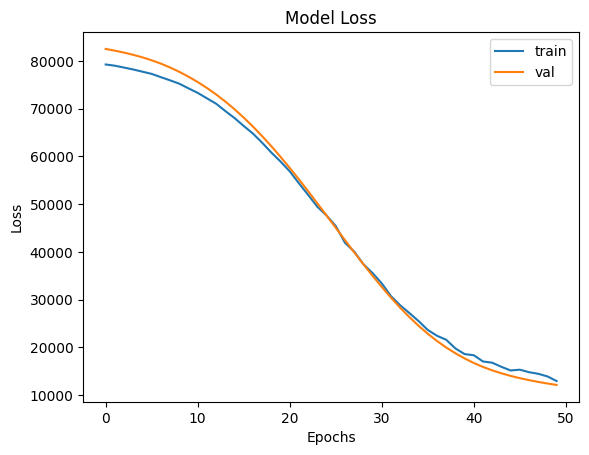

In [19]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['train', 'val'])
plt.show()

In [ ]:
# (14) 정답을 입력하세요 — `정답14` 에 값만 넣고 실행하세요

정답14 = 'history'

<details><summary>힌트 1단계 (접근 방향) - 14번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. fit 이 돌려준 학습 기록 객체의 변수명입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 14번 문항</summary>

사용할 도구: `plt.plot`, `plt.title`, `plt.xlabel`, `plt.ylabel`, `plt.legend`, `plt.show`. 정답은 7글자이고 첫 글자는 `h` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 14번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
plt.plot(hist___.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['train', 'val'])
plt.show()

정답14 = 'hist___'   # 빈칸에 넣은 단어
```

</details>